# From deposit and OIS quotes to a discount curve

A discount curve translates today's market quotes into values for future
payments. We construct a USD SOFR curve from the illustrative deposit and
OIS quotes dated 24 February 2026, then use it to value a payment and calculate
a forward rate.

The curve configuration selects the calibration instruments and interpolation
conventions. After construction, we inspect its discount factors and check
both deposit repricing and the relationship between discount factors and
forwards. [Setup and notebook catalog](../README.md).


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import quantsupport as qs
from market_data import load_market

market = load_market()
reference_date = market.quotes.reference_date
print("Reference date:", reference_date)
market.quotes.to_dataframe().head(8)


Reference date: 2026-02-24


,identifier,mid,bid,ask
0,CapletFloorlet_USD_SOFR_3M_10Y_Absolute_0.035_...,0.20,None,None
1,CapletFloorlet_USD_SOFR_3M_10Y_Absolute_0.045_...,0.18,None,None
2,CapletFloorlet_USD_SOFR_3M_10Y_Absolute_0.055_...,0.20,None,None
3,CapletFloorlet_USD_SOFR_3M_12Y_Absolute_0.035_...,0.19,None,None
4,CapletFloorlet_USD_SOFR_3M_12Y_Absolute_0.045_...,0.17,None,None
5,CapletFloorlet_USD_SOFR_3M_12Y_Absolute_0.055_...,0.19,None,None
6,CapletFloorlet_USD_SOFR_3M_1Y_Absolute_0.035_S...,0.33,None,None
7,CapletFloorlet_USD_SOFR_3M_1Y_Absolute_0.045_S...,0.29,None,None


## Configuring the bootstrap

The local loader supplies the SOFR quotes and curve specification. Each quote
identifier defines a calibration instrument, including its tenor and market
conventions. The configuration's `quotes` list selects the observations used
to solve the curve.

We reconstruct the loaded configuration from its dictionary so its inputs are
visible. Edit this specification to change calibration instruments or numerical
conventions; the same schema can be loaded from a file with `from_json`.


In [2]:
specification = market.curves[0].to_dict()
configuration = qs.CurveConfiguration.from_dict(specification)
specification


{'market_index': 'SOFR',
 'construction': {'type': 'Bootstrapped'},
 'day_counter': 'Actual360',
 'interpolator': 'LogLinear',
 'enable_extrapolation': True,
 'quotes': ['FixedRateDeposit_USD_SOFR_1D',
  'OIS_USD_SOFR_1Y',
  'OIS_USD_SOFR_2Y',
  'OIS_USD_SOFR_3Y',
  'OIS_USD_SOFR_5Y',
  'OIS_USD_SOFR_7Y',
  'OIS_USD_SOFR_10Y',
  'OIS_USD_SOFR_30Y']}

## Constructing and inspecting the curve

A pricing context combines the observations and configuration. Entering
`with context:` activates the valuation scope; requesting the SOFR curve
constructs it and its dependencies.

The node table contains interpolation dates and solved discount factors.
The pillar table identifies the market inputs used for sensitivities. We copy
both tables and the scalar query results out of the scope, since live curve
views depend on the context's market and differentiation state.


In [ ]:
context = qs.PricingContext(
    quotes=market.quotes, 
    curves=[configuration], 
    csa_policy=market.csa_policy
)

with context:
    curve = context.curve(qs.MarketIndex.SOFR)
    nodes = curve.nodes()
    pillars = curve.pillars()
    day_counter = curve.day_counter
    interval_start, interval_end = reference_date + "1Y", reference_date + "1Y3M"
    start_discount_factor, end_discount_factor = curve.discount_factor(
        interval_start
    ), curve.discount_factor(interval_end)
    forward = curve.forward_rate(
        interval_start, interval_end, qs.Compounding.Simple, qs.Frequency.Annual
    )

print("Curve day count:", day_counter)
pillars


Curve day count: Actual360


,label,value
0,FixedRateDeposit_USD_SOFR_1D,0.04500
1,OIS_USD_SOFR_1Y,0.04837
2,OIS_USD_SOFR_2Y,0.04528
3,OIS_USD_SOFR_3Y,0.04260
4,OIS_USD_SOFR_5Y,0.04077
5,OIS_USD_SOFR_7Y,0.04033
6,OIS_USD_SOFR_10Y,0.03898
7,OIS_USD_SOFR_30Y,0.03738


## Valuing a payment and calculating a forward

For this single-curve USD market, a deterministic USD 100 payment is worth
100 times the discount factor at its payment date. A simple forward over
$[S,T]$ follows from the ratio of discount factors:

$$F(S,T)=\frac{P(0,S)/P(0,T)-1}{\tau(S,T)}.$$

We calculate the accrual fraction using the curve's day counter and compare
the result with its forward-rate query.


In [4]:
accrual = day_counter.year_fraction(interval_start, interval_end)
forward_from_discount_factors = (
    start_discount_factor / end_discount_factor - 1
) / accrual
pd.Series(
    {
        "interval_start_df": start_discount_factor,
        "interval_end_df": end_discount_factor,
        "simple_forward_rate": forward,
        "forward_from_discount_factors": forward_from_discount_factors,
        "forward_rate_difference": forward - forward_from_discount_factors,
        "usd_100_at_interval_end_pv": 100 * end_discount_factor,
    }
)


interval_start_df                 0.953257
interval_end_df                   0.943517
simple_forward_rate               0.041757
forward_from_discount_factors     0.041757
forward_rate_difference           0.000000
usd_100_at_interval_end_pv       94.351664
dtype: float64

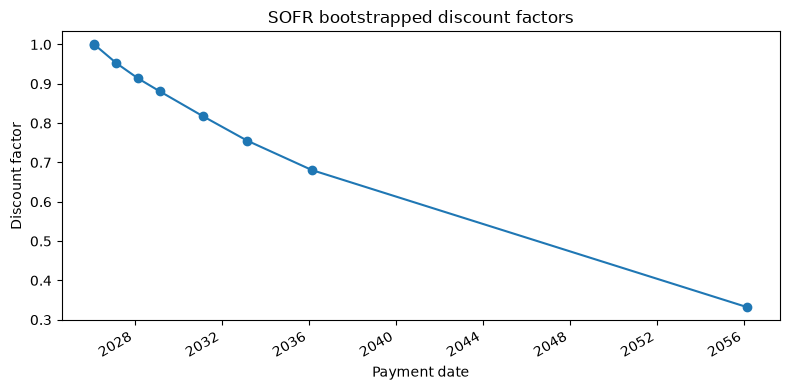

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(pd.to_datetime(nodes["date"]), nodes["discount_factor"], marker="o")
ax.set(
    title="SOFR bootstrapped discount factors",
    xlabel="Payment date",
    ylabel="Discount factor",
)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


## Deposit repricing and zero rates

The one-day deposit provides a calibration check. Its quoted rate $q$ should
satisfy $P(0,T)=1/(1+q\tau)$ under its contractual accrual convention. We also check the forward identity above.

To express the curve as continuously compounded zero rates, calculate $z(T)=-\log P(0,T)/t $. These rates describe discounting to each maturity; OIS par quotes describe the fixed coupons of their calibration contracts.


In [6]:
import math

deposit_label = configuration.to_dict()["quotes"][0]
quotes = market.quotes.to_dataframe().set_index("identifier")
deposit_quote = float(quotes.loc[deposit_label, "mid"])
deposit_end = reference_date + "1D"
deposit_accrual = qs.DayCounter.Actual360.year_fraction(reference_date, deposit_end)
with context:
    deposit_df = context.curve(qs.MarketIndex.SOFR).discount_factor(deposit_end)
deposit_implied = (1 / deposit_df - 1) / deposit_accrual

zero_rates = nodes.copy()
zero_rates["time_years"] = zero_rates["date"].map(
    lambda date: day_counter.year_fraction(reference_date, qs.Date.parse(date))
)
zero_rates = zero_rates.loc[zero_rates["time_years"] > 0].copy()
zero_rates["continuous_zero_rate"] = [
    -math.log(discount) / time
    for discount, time in zip(zero_rates["discount_factor"], zero_rates["time_years"])
]
print(f"One-day deposit repricing residual: {deposit_implied - deposit_quote:.3e}")
print(f"Forward identity residual: {forward - forward_from_discount_factors:.3e}")
print(f"USD 100 due {interval_end} is worth USD {100 * end_discount_factor:.4f} today.")
zero_rates[["date", "discount_factor", "continuous_zero_rate"]]


One-day deposit repricing residual: -2.494e-14
Forward identity residual: 0.000e+00
USD 100 due 2027-05-24 is worth USD 94.3517 today.


,date,discount_factor,continuous_zero_rate
1,2026-02-25,0.999875,0.044997
2,2027-03-02,0.952507,0.047215
3,2028-03-01,0.913601,0.044199
4,2029-02-28,0.880772,0.041549
5,2031-02-28,0.817031,0.039753
6,2033-03-02,0.755705,0.039344
7,2036-02-28,0.680452,0.037910
8,2056-03-01,0.331810,0.036226


Interpolation determines values between calibration pillars. Compare the
zero-rate table with the supplied deposit and OIS quotes to see how those
contract quotations translate into the constructed curve. The falling discount
factors here reflect the positive rates in this snapshot; negative-rate
markets can produce a different shape.

Continue with [swap valuation](../valuation/swaps/tour.ipynb) to use the curve
in a pricer, or [curves and volatility shocks](../volatilitysurface/curves_and_volatility.ipynb)
to examine how changed inputs affect trade values. The
[portfolio-risk study](../sensitivity/portfolio_risk.ipynb) follows the same
quote labels into aggregated sensitivities.
